(paramfit_ntbk)=

# Parameters fit with pyABC

This is a simple example of how we can use a package like [pyABC](https://pyabc.readthedocs.io/) to estimate the fundamental parameters for an observed cluster, using a simple distance defined by the user. The likelihood built into **ASteCA** is only used by its own [Sampler](asteca.Sampler) (see the [Parameters fit with asteca.Sampler](paramfit_sampler_ntbk) tutorial; the [Parameters fit with pocoMC](paramfit_pocomc_ntbk) tutorial shows a user-defined likelihood with an external sampler); here we show how the synthetic clusters can be combined with any likelihood or distance. The user can combine **ASteCA** with any other package of their choosing, here's a list with many Python-based [MCMC and ABC packages](https://gabriel-p.github.io/pythonMCMC/).

## Loading ASteCA objects

We start by instantiating an [Isochrones](asteca.Isochrones) object with a PARSEC isochrone. This is an example file but you can use whatever isochrone service fits your needs:

In [1]:
import asteca

# Load isochrones
isochs = asteca.Isochrones(
    model='parsec',
    isochs_path="../../_static/isochrones/parsec/",
    mag="Gmag",
    color=("G_BPmag", "G_RPmag"),
    magnitude_effl=6390.7,
    color_effl=(5182.58, 7825.08),
    verbose=2
)


Instantiating isochrones
Model          : PARSEC
N_files        : 1
N_mets         : 5
N_ages         : 13
N_points       : 2000
z    range     : [0.01, 0.03]
loga range     : [7.0, 10.0]
Magnitude      : Gmag
Color          : G_BPmag-G_RPmag
Isochrone object generated


Next we instantiate a [Synthetic](asteca.Synthetic) object, passing the `isochs` object we just created (we are using all defaults for the arguments here):

In [2]:
# Create Synthetic cluster object
synthcl = asteca.Synthetic(isochs, seed=457304, verbose=2)


Instantiating synthetic
(Sampling IMF)
Default params : {'met': 0.0152, 'loga': 8.0, 'alpha': 0.09, 'beta': 0.94, 'Rv': 3.1, 'DR': 0.0, 'Av': 0.2, 'dm': 9.0}
Extinction law : CCMO
Diff reddening : foreground
IMF            : chabrier_2014
Max init mass  : 10000
Gamma dist     : D&K
Random seed    : 457304
Synthetic clusters object generated


Now we load our observed cluster into a [Cluster](asteca.Cluster) object:

In [3]:
import pandas as pd

obs_df = pd.read_csv("../../_static/cluster.csv")

my_cluster = asteca.Cluster(
    ra=obs_df["RA_ICRS"],
    dec=obs_df["DE_ICRS"], 
    mag=obs_df["Gmag"],
    e_mag=obs_df["e_Gmag"],
    color=obs_df["BP-RP"],
    e_color=obs_df["e_BP-RP"],
    verbose=2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color
N_stars        : 1428
N_nan_phot     : 9
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


We assume that the cluster file loaded in `obs_df` is composed of only the most probable members of the cluster. If not, you can refer to the [Membership probabilities](membership) tutorial to learn how to obtain the membership probabilities and select the most probable members.

Finally, we need to calibrate our `synthcl` object with the `my_cluster` object we generated above, so that the synthetic clusters have the same number of stars, maximum magnitude, and photometric uncertainties as the observed cluster.

In [4]:
# Calibrate the `synthcl` object
synthcl.calibrate(my_cluster)


Calibrated observed cluster
N_stars_obs    : 1419
Max magnitude  : 18.99
Error distribution loaded


## Running pyABC

We are now ready to begin the fundamental parameters estimation process with pyABC. The first step is to import pyABC and define the priors for the parameters that are being estimated, as well as a dictionary with the remaining fundamental parameters that are *not* being estimated and are thus fixed to a certain value.

Notice that the priors defined this way for pyABC require using the minimum value and the desired *range*, not the maximum value.

In [5]:
import pyabc

met_min, met_max = 0.01, 0.02
loga_min, loga_max = 7.0, 9.5
dm_min, dm_max = 8.0, 10.5
Av_min, Av_max = 0.0, 2.0

# Define a pyABC Distribution(). Uniform distributions are employed for all the parameters
# here but the user can of course change this as desired. See the pyABC docs for more
# information.
priors = pyabc.Distribution(
    {
        "met": pyabc.RV("uniform", met_min, met_max - met_min),
        "loga": pyabc.RV("uniform", loga_min, loga_max - loga_min),
        "dm": pyabc.RV("uniform", dm_min, dm_max - dm_min),
        "Av": pyabc.RV("uniform", Av_min, Av_max - Av_min)
    }
)

pyABC works by minimizing the distance between our data (the observed cluster) and synthetic data (the synthetic clusters). We will need two convenience functions to do this.

The first function required is `model()` which takes a dictionary with the fundamental parameters being estimated by pyABC, generates a synthetic cluster via the `generate()` method, and returns it as a dictionary. The returned variable is a dictionary simply because this is what pyABC expects; this is not a requirement of **ASteCA**.

In [6]:
def model(fit_params):
    """Generate a synthetic cluster."""
    # Call generate method with the fit_params dictionary
    synth_clust = synthcl.generate(fit_params)

    # pyABC expects a dictionary from this function, so we return a
    # dictionary with a single element.
    return {"data": synth_clust}

We then define a `distance()` function that quantifies how different the observed and synthetic clusters are, which pyABC will *minimize*. Any function can be used here; we use a simple one: the observed and synthetic stars are binned into a fixed Hess diagram (the CMD split into cells, spanning the observed cluster), and the distance is the [total variation distance](https://en.wikipedia.org/wiki/Total_variation_distance_of_probability_measures) between the two normalized histograms. It goes from `0` (the same fraction of stars in every cell) to `1` (no synthetic star in any of the cells occupied by observed stars). Synthetic stars outside of the observed CMD count as a mismatch, and empty synthetic clusters get the maximum distance.

Notice that this function receives two arguments from pyABC but we only require one, hence the second argument is dismissed. The function makes use of the dictionary generated by the `model()` function, containing the synthetic cluster, whose first two rows are its magnitude and color.

In [7]:
import numpy as np

# Observed stars with valid photometry
msk = np.isfinite(my_cluster.mag) & np.isfinite(my_cluster.color)
obs_mag, obs_col = my_cluster.mag[msk], my_cluster.color[msk]

# Fixed Hess diagram, spanning the observed CMD
mag_edges = np.linspace(obs_mag.min(), obs_mag.max(), 21)
col_edges = np.linspace(obs_col.min(), obs_col.max(), 16)
H_obs = np.histogram2d(obs_mag, obs_col, bins=(mag_edges, col_edges))[0]
H_obs /= H_obs.sum()


def distance(synth_dict, _):
    """Total variation distance between the observed and synthetic Hess diagrams:
    0 means the same distribution and 1 means no overlap."""
    synth = synth_dict["data"]
    if synth.size == 0:
        return 1.0
    H_syn = np.histogram2d(synth[0], synth[1], bins=(mag_edges, col_edges))[0]
    # Normalize by the total number of synthetic stars
    H_syn /= synth.shape[1]
    # Fraction of synthetic stars outside of the observed CMD, counted as a mismatch
    f_out = 1.0 - H_syn.sum()
    return 0.5 * (np.abs(H_obs - H_syn).sum() + f_out)

We create an [ABCSMC](https://pyabc.readthedocs.io/en/latest/api/pyabc.inference.html#pyabc.inference.ABCSMC) object with the `model` and `distance` functions, as well as the priors defined earlier. A population of 100 is usually enough. A single core sampler and a fixed random seed are used so that the results are reproducible; remove the `sampler` argument to use pyABC's default multicore sampler (faster, but not reproducible). The tempfile defined below is required by pyABC.

In [8]:
# Fix pyABC's random seed for reproducibility. This only works with the single core
# sampler: pyABC's default multicore sampler re-seeds each worker process randomly
np.random.seed(457304)

# Define pyABC parameters
pop_size = 100
abc = pyabc.ABCSMC(
    model,
    priors,
    distance,
    population_size=pop_size,
    sampler=pyabc.sampler.SingleCoreSampler(),
)

# Define a temporary file required by pyABC
import os
import tempfile
db_path = "sqlite:///" + os.path.join(tempfile.gettempdir(), "pyABC.db")
abc.new(db_path)

ABC.History INFO: Start <ABCSMC id=1, start_time=2026-11-11 09:46:52>


Finally, we can run pyABC to perform Approximate Bayesian Inference on our parameters. We set a small number of populations here as an example. Running for ~2 minutes is usually enough (see pyABC's documentation on how to set up a maximum running time):

In [9]:
history = abc.run(minimum_epsilon=0.01, max_nr_populations=20)

ABC INFO: Calibration sample t = -1.
ABC INFO: t: 0, eps: 6.59619450e-01.
ABC INFO: Accepted: 100 / 194 = 5.1546e-01, ESS: 1.0000e+02.
ABC INFO: Timing t=0 [s]: total=0.537, simulation=0.361 (67%), pipeline-setup=0.00825, prepare-next=0.0475 (population-size=0.0166, distance=0.0028).
ABC INFO: t: 1, eps: 4.67582805e-01.
ABC INFO: Accepted: 100 / 260 = 3.8462e-01, ESS: 7.2367e+01.
ABC INFO: Timing t=1 [s]: total=1.09, simulation=0.765 (70%), pipeline-setup=0.00537, prepare-next=0.0372 (population-size=0.0164, distance=0.00415).
ABC INFO: t: 2, eps: 4.03805497e-01.
ABC INFO: Accepted: 100 / 222 = 4.5045e-01, ESS: 6.0923e+01.
ABC INFO: Timing t=2 [s]: total=0.9, simulation=0.676 (75%), pipeline-setup=0.00603, prepare-next=0.0426 (population-size=0.0148, distance=0.00298).
ABC INFO: t: 3, eps: 3.59293954e-01.
ABC INFO: Accepted: 100 / 248 = 4.0323e-01, ESS: 8.0644e+01.
ABC INFO: Timing t=3 [s]: total=0.83, simulation=0.659 (79%), pipeline-setup=0.00554, prepare-next=0.0524 (population-size

## Extracting the results

We are now ready to extract a few important results, along with our fundamental parameters' estimations.

The first line shows the final minimized distance between our observed cluster and the synthetic clusters that were generated. Its value depends on the distance function defined above (and for this one, on the number of stars and of cells), so it is only useful to compare synthetic clusters for this observed cluster.

The following line extracts the DataFrame of the last run, and its associated weights. We use the weights to show the effective sample size. This value depends on the population size used above (`pop_size`) and should be large enough to allow decent mean/median/STDDEV values to be extracted.

In [10]:
final_dist = pyabc.inference_util.eps_from_hist(history)
print("Final minimized distance: {:.2f} ({:.0f}%)".format(final_dist, 100*final_dist))

# Extract last iteration and weights
df, w = history.get_distribution()

ESS = pyabc.weighted_statistics.effective_sample_size(w)
print("Effective sample size: {:.0f}".format(ESS))

Final minimized distance: 0.17 (17%)
Effective sample size: 41


Finally, the estimations for each fitted parameter is extracted from the DataFrame using the associated weights (again, this is a [pyABC dependent method](https://pyabc.readthedocs.io/en/latest/api/pyabc.weighted_statistics.html#api-weighted-statistics); other packages will do this differently)

In [11]:
print("\nParameters estimation:")
print("----------------------")
fit_params = {}
for k in df.keys():
    # Extract medians for the fitted parameters
    _median = pyabc.weighted_statistics.weighted_median(df[k].values, w)
    fit_params[k] = _median
    # Extract STDDEV for the fitted parameters
    _std = pyabc.weighted_statistics.weighted_std(df[k].values, w)
    print("{:<5}: {:.3f} +/- {:.3f}".format(k, _median, _std))


Parameters estimation:
----------------------
Av   : 0.534 +/- 0.115
dm   : 8.151 +/- 0.034
loga : 7.946 +/- 0.107
met  : 0.012 +/- 0.003


pyABC has many methods to visualize and analyze the results, see [Visualization and analysis](https://pyabc.readthedocs.io/en/latest/visualization.html#visualization-and-analysis). We show here just a few:

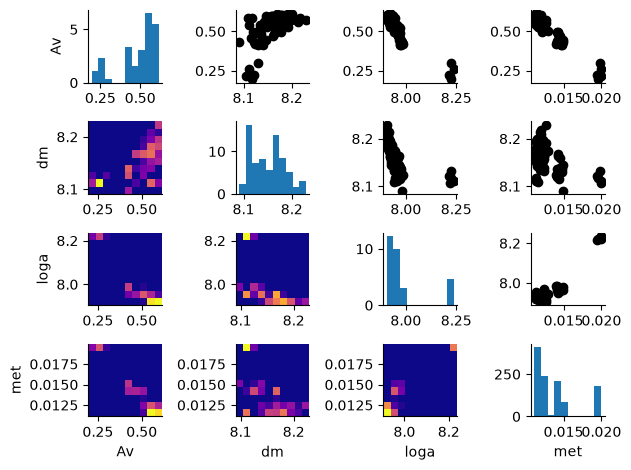

In [12]:
pyabc.settings.set_figure_params("pyabc")  # for beautified plots

# Matrix of 1d and 2d histograms over all parameters
pyabc.visualization.plot_histogram_matrix(history);

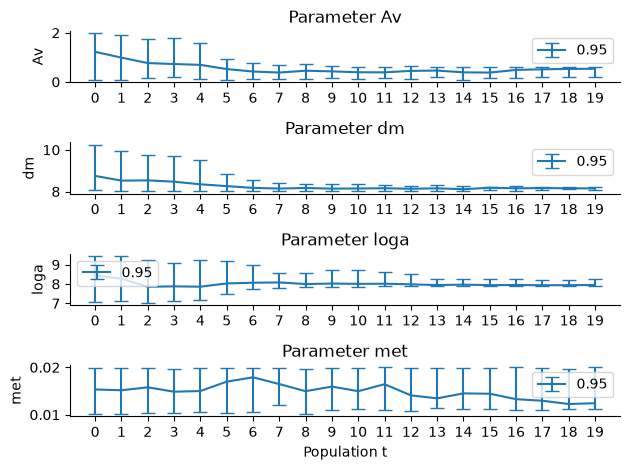

In [13]:
# Credible intervals over time
pyabc.visualization.plot_credible_intervals(history);

See the [Goodness of fit](paramfit_gof_ntbk) tutorial to assess whether the synthetic cluster generated with these parameters is a good representation of the observed cluster.